# Финальный экзамен. Анализ плей-офф НХЛ 2025/2026

В работе использован файл `NHL-playoffs-2026.xlsx`. Все результаты получены непосредственно из исходных событий матчей.

In [ ]:
# Подключаю библиотеки для таблиц, расчетов и графиков.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', 140)

## Задача 1. Чтение данных

In [ ]:
# Загружаю Excel и оставляю первый столбец как индекс исходной таблицы.
# Первый столбец в Excel является старым индексом, поэтому читаю его как индекс
# и в самом наборе событий остается 38 содержательных полей.
events = pd.read_excel('NHL-playoffs-2026.xlsx', index_col=0)

print('Размер набора данных:', events.shape)
print(events.iloc[:10, [2, 3, 4, 9, 12]])

Размер набора данных: (29710, 38)
         Date      Away Team       Home Team Remaining Time     Play Type
0  2026-04-19  Boston Bruins  Buffalo Sabres          20:00  period-start
1  2026-04-19  Boston Bruins  Buffalo Sabres          20:00       faceoff
2  2026-04-19  Boston Bruins  Buffalo Sabres          19:47           hit
3  2026-04-19  Boston Bruins  Buffalo Sabres          19:46           hit
4  2026-04-19  Boston Bruins  Buffalo Sabres          19:41           hit
5  2026-04-19  Boston Bruins  Buffalo Sabres          19:27           hit
6  2026-04-19  Boston Bruins  Buffalo Sabres          19:03           hit
7  2026-04-19  Boston Bruins  Buffalo Sabres          18:53   missed-shot
8  2026-04-19  Boston Bruins  Buffalo Sabres          18:48           hit
9  2026-04-19  Boston Bruins  Buffalo Sabres          18:37   missed-shot


В таблице 29 710 событий и 38 полей. В первых строках видны дата, команды, оставшееся время и тип события, поэтому данные прочитались в нужном виде.

## Задача 2. Краткая информация по каждой игре

In [ ]:
# Последняя запись игры содержит окончательный счет и номер последнего периода.
last_events = events.sort_values(['Game ID', 'Play ID']).groupby('Game ID').tail(1)

games = last_events.set_index('Game ID')[
    ['Date', 'Away Team', 'Home Team',
     'Cumulated Away Score', 'Cumulated Home Score', 'Period']
].copy()

games = games.rename(columns={
    'Cumulated Away Score': 'Away Score',
    'Cumulated Home Score': 'Home Score'
})

games['Outcome'] = 'Final'
for game_id in games.index:
    period = games.loc[game_id, 'Period']
    if period == 4:
        games.loc[game_id, 'Outcome'] = 'Final/OT'
    elif period > 4:
        games.loc[game_id, 'Outcome'] = f"Final/{int(period - 3)}OT"

games = games.drop(columns='Period')
games.index.name = 'Game ID'

print('Количество игр:', len(games))
print(games.columns)
print(games.iloc[-5:, -4:])

Количество игр: 82
Index(['Date', 'Away Team', 'Home Team', 'Away Score', 'Home Score', 'Outcome'], dtype='object')
                       Home Team  Away Score  Home Score    Outcome
Game ID                                                            
2025030412   Carolina Hurricanes           3           4   Final/OT
2025030413  Vegas Golden Knights           4           5  Final/2OT
2025030414  Vegas Golden Knights           5           3      Final
2025030415   Carolina Hurricanes           2           4      Final
2025030416  Vegas Golden Knights           3           0      Final


Сводная таблица содержит ровно одну строку на матч, поэтому всего получилось 82 игры. Индексом оставлен `Game ID`, а в таблице есть дата, команды гостей и хозяев, их итоговые счета и результат по длительности игры. Итоговый счет берется из последней записи матча: к этому моменту накопленные счета уже включают все голы. Значение `Final/OT` означает один овертайм, а `Final/2OT` — два овертайма.

## Задача 3. Функция `gameInfo(gameId)`

In [ ]:
# Формирую короткое описание игры в том же порядке, что и в условии.
def gameInfo(gameId):
    game = games.loc[gameId]
    return (f"{game['Home Team']} - {game['Away Team']} "
            f"({int(game['Home Score'])} - {int(game['Away Score'])}, "
            f"{game['Outcome']}, {game['Date']})")

print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


Функция получает идентификатор игры, находит строку этой игры в сводной таблице и собирает из нее готовую строку. В выводе команды и счета расположены в порядке «хозяева — гости», как в примере из условия. Такой формат удобен дальше: вместо повторения нескольких обращений к `games` можно напечатать информацию о матче одной командой.

## Задача 4. Общее число голов и описательные статистики

In [ ]:
# Суммирую итоговые голы хозяев и гостей для каждого матча.
games['Total Score'] = games['Away Score'] + games['Home Score']
print(games['Total Score'].describe().round(3))

count    82.000
mean      5.927
std       2.260
min       1.000
25%       5.000
50%       6.000
75%       7.000
max      15.000
Name: Total Score, dtype: float64


В каждой игре складываются голы обеих команд. Среднее значение 5.927 означает типичный уровень результативности плей-офф, а медиана 6 показывает, что половина матчей имела не больше шести голов и половина — не меньше. Стандартное отклонение около 2.260 говорит о заметном разбросе: рядом с обычными матчами встречались игры от 1 до 15 голов. Квантили 5 и 7 показывают, что центральные 50% наблюдений лежат примерно между 5 и 7 голами.

## Задача 5. Гистограмма числа голов за матч

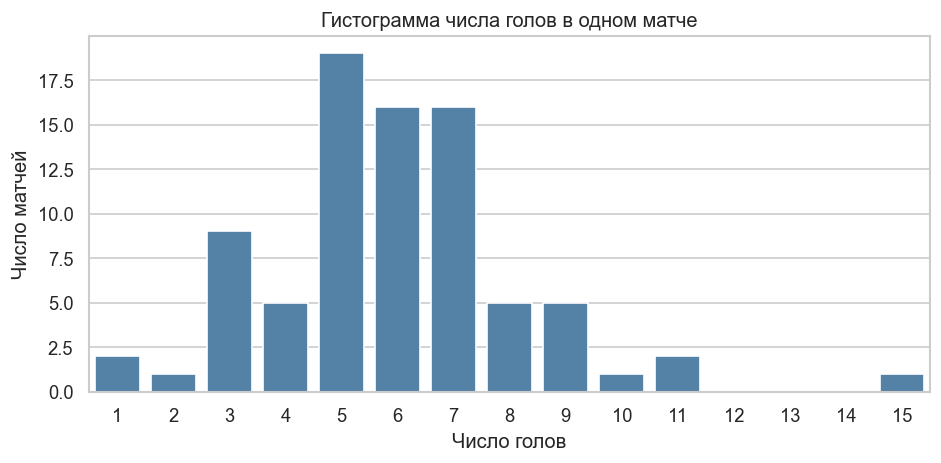

In [ ]:
# Для каждого целого числа голов считаю, сколько матчей его имели.
plt.figure(figsize=(8, 4))
order = range(int(games['Total Score'].min()), int(games['Total Score'].max()) + 1)
sns.countplot(data=games, x='Total Score', order=order, color='steelblue')
plt.xlabel('Число голов')
plt.ylabel('Число матчей')
plt.title('Гистограмма числа голов в одном матче')
plt.tight_layout()
plt.show()

На графике видны все значения от 1 до 15, включая нулевые частоты для 12, 13 и 14 голов. Наиболее высокая колонка соответствует пяти голам: таких матчей 19. Значения 6 и 7 встречаются по 16 раз, поэтому наиболее типичный матч имеет 5–7 шайб. Длинный правый хвост создается редкими результативными играми, прежде всего матчем с 15 голами.

## Задача 6. Самые нерезультативные и самые результативные игры

In [ ]:
# Сначала нахожу минимальный и максимальный общий счет, затем вывожу все такие игры.
minimum = games['Total Score'].min()
maximum = games['Total Score'].max()

not_resultative = [gameInfo(game_id) for game_id in games.index
                   if games.loc[game_id, 'Total Score'] == minimum]
resultative = [gameInfo(game_id) for game_id in games.index
               if games.loc[game_id, 'Total Score'] == maximum]

print('Самые нерезультативные игры:')
print(not_resultative)
print('\nСамые результативные игры:')
print(resultative)

Самые нерезультативные игры:
['Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)', 'Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']

Самые результативные игры:
['Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)']


Минимальный суммарный счет равен 1: обе такие игры завершились со счетом 1:0 уже в овертайме, то есть победная шайба была забита после основного времени. Самый большой счет — 15 голов в матче Colorado Avalanche — Minnesota Wild, 9:6. В списках сохранены все игры, имеющие одинаковый минимум или максимум, а не только первая найденная строка.

## Задача 7. Число игроков, участвовавших в каждой игре

In [ ]:
# Собираю уникальных хоккеистов из всех записей состава на льду.
players_columns = []
for side in ['Away', 'Home']:
    for number in range(1, 7):
        players_columns.append(f"{side} Team's Player on the Ice #{number}")
    players_columns.append(f"{side} Team's Goalie")

players_count = []
for game_id in games.index:
    one_game = events[events['Game ID'] == game_id]
    players = []
    for column in players_columns:
        players += one_game[column].dropna().tolist()
    players_count.append([game_id, len(set(players))])

players_count = pd.DataFrame(players_count, columns=['Game ID', 'Player Count'])
players_count = players_count.set_index('Game ID')
players_count['Game Info'] = [gameInfo(game_id) for game_id in players_count.index]
players_count = players_count[['Game Info', 'Player Count']]

max_players = players_count['Player Count'].max()
print(players_count[players_count['Player Count'] == max_players])

                                                    Game Info  Player Count
Game ID                                                                    
2025030216  Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...            40


Игроки собираются из всех полей состава на льду для обеих команд, включая отдельные поля вратарей. Затем одинаковые фамилии объединяются через `set`, поэтому один и тот же игрок, появлявшийся в нескольких событиях, считается один раз. Пропуски не являются игроками и исключаются. Максимум равен 40; расхождение с числом 41 в иллюстративном примере связано с тем, что там, вероятно, был посчитан один пропуск.

## Задача 8. Расстояние броска до ворот

In [ ]:
# Оставляю только события трех типов бросков и рассчитываю расстояние до ближайшей точки ворот.
# Для расстояния нужны только точные, голевые и неточные броски.
shots = events[events['Play Type'].isin(['shot-on-goal', 'goal', 'missed-shot'])].copy()
side_column = "Home Team's Defending Side"

# X координата нужных ворот зависит от стороны, которую защищают хозяева.
def shot_length(row):
    x = row['X Coordinate on the Ice Rink']
    y = row['Y Coordinate on the Ice Rink']
    if pd.isna(x) or pd.isna(y):
        return np.nan

    home_shot = row['Team Making the Play'] == row['Home Team']
    if row[side_column] == 'left':
        goal_x = 89 if home_shot else -89
    else:
        goal_x = -89 if home_shot else 89

    if y < -3:
        return np.sqrt((x - goal_x) ** 2 + (y + 3) ** 2)
    elif y <= 3:
        return abs(x - goal_x)
    else:
        return np.sqrt((x - goal_x) ** 2 + (y - 3) ** 2)

shots['Shot Length'] = shots.apply(shot_length, axis=1)
print(shots[['Game ID', 'Play Type', 'X Coordinate on the Ice Rink',
               'Y Coordinate on the Ice Rink', 'Shot Length']].head())
print('Число бросков:', len(shots))
print('Пропуски расстояния:', shots['Shot Length'].isna().sum())
print(shots.groupby('Play Type')['Shot Length'].agg(['count', 'mean', 'min', 'max']).round(3))

       Game ID     Play Type  X Coordinate on the Ice Rink  Y Coordinate on the Ice Rink  Shot Length
7   2025030111   missed-shot                          82.0                         -13.0    12.206556
9   2025030111   missed-shot                         -77.0                           2.0    12.000000
12  2025030111   missed-shot                          65.0                          20.0    29.410882
13  2025030111  shot-on-goal                          28.0                          15.0    62.169124
19  2025030111   missed-shot                          40.0                         -23.0    52.924474
Число бросков: 7266
Пропуски расстояния: 0
              count    mean  min      max
Play Type                                
goal            486  26.006  1.0  187.216
missed-shot    2643  34.014  0.0  185.068
shot-on-goal   4137  37.405  0.0  188.215


Расстояние считается в футах и не требует перевода единиц. Сначала выбираются правильные ворота: для хозяев и гостей направление зависит от `Home Team's Defending Side`. Затем применяется кусочная формула из условия: если координата `y` находится напротив створа, берется горизонтальное расстояние, а за пределами створа — расстояние до ближайшего края ворот. В итоге обработаны все 7 266 точных, голевых и неточных бросков, и ни одного пропуска расстояния не осталось.

## Задача 9. Распределения точных и неточных бросков

Средние и медианные расстояния:
         count    mean  median
Shot                          
missed    2643  34.014  32.249
on goal   4623  36.207  31.828


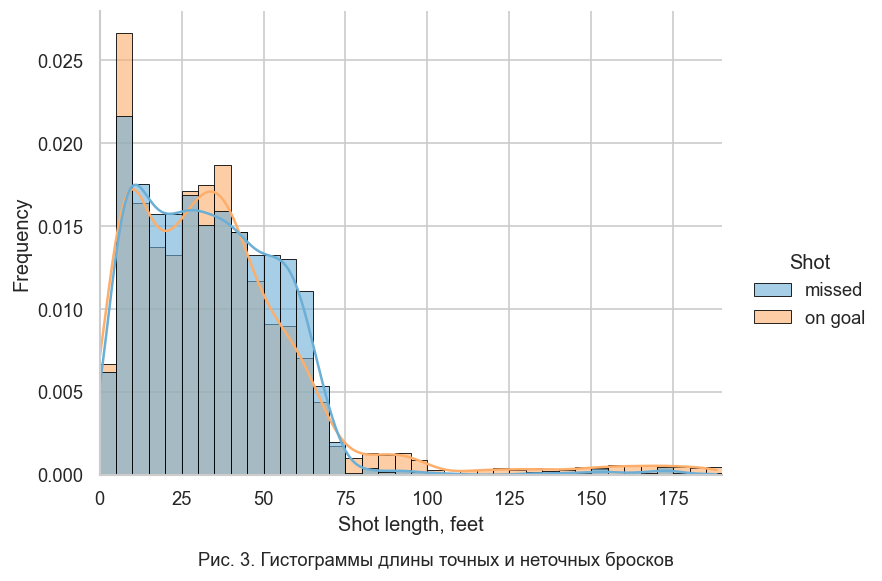

In [ ]:
# Сравниваю распределения промахов и бросков в створ в одинаковых интервалах.
shots['Shot'] = np.where(
    shots['Play Type'].eq('missed-shot'), 'missed', 'on goal'
)

plot = sns.displot(
    data=shots,
    x='Shot Length',
    hue='Shot',
    hue_order=['missed', 'on goal'],
    palette={'missed': '#6baed6', 'on goal': '#fdae6b'},
    stat='density',
    common_norm=False,
    common_bins=True,
    bins=np.arange(0, 191, 5),
    multiple='layer',
    kde=True,
    alpha=0.60,
    edgecolor='black',
    linewidth=0.5,
    height=4.7,
    aspect=1.35,
    legend=True
)
plot.set_axis_labels('Shot length, feet', 'Frequency')
plot.set(xlim=(0, 190))
if plot._legend is not None:
    plot._legend.set_title('Shot')
plt.figtext(0.5, -0.02,
            'Рис. 3. Гистограммы длины точных и неточных бросков',
            ha='center', fontsize=11)
plt.show()

print('Средние и медианные расстояния:')
print(shots.groupby('Shot')['Shot Length'].agg(['count', 'mean', 'median']).round(3))

Для сравнения «точные» объединены как `shot-on-goal` и `goal`, потому что гол является броском, дошедшим до ворот. Частоты нормированы отдельно для двух групп (`common_norm=False`), поэтому разный размер подвыборок не искажает сравнение высот. Основная масса обоих распределений расположена примерно между 10 и 60 футами; медианы почти одинаковы (31.828 и 32.249 фута). При этом у точных бросков среднее немного больше из-за длинного хвоста, доходящего почти до 190 футов. Такой хвост может возникать из-за дальних бросков и выбросов шайбы со своей половины, которые были зафиксированы как дошедшие до ворот, а также из-за бросков по пустым воротам.

## Задача 10. Доля точных бросков у каждой команды в каждой игре

In [ ]:
# Для каждой команды в каждой игре отдельно считаю точные и все незаблокированные броски.
# Заблокированные броски не входят в знаменатель.
shots_for_share = events[events['Play Type'].isin(
    ['shot-on-goal', 'goal', 'missed-shot']
)].copy()
shots_for_share['On Goal'] = shots_for_share['Play Type'].isin(
    ['shot-on-goal', 'goal']
)

numshots = shots_for_share.groupby(
    ['Game ID', 'Team Making the Play']
)['On Goal'].agg(['sum', 'count'])
numshots = numshots.rename(columns={
    'sum': 'Shots on Goal',
    'count': 'Unblocked Shots'
})
numshots['Share of Shots on Goal'] = (
    numshots['Shots on Goal'] / numshots['Unblocked Shots']
)

print(numshots.head(10).round(3))

                                 Shots on Goal  Unblocked Shots  Share of Shots on Goal
Game ID    Team Making the Play                                                        
2025030111 Boston Bruins                    20               32                   0.625
           Buffalo Sabres                   38               56                   0.679
2025030112 Boston Bruins                    27               44                   0.614
           Buffalo Sabres                   35               55                   0.636
2025030113 Boston Bruins                    25               36                   0.694
           Buffalo Sabres                   30               44                   0.682
2025030114 Boston Bruins                    24               40                   0.600
           Buffalo Sabres                   35               54                   0.648
2025030115 Boston Bruins                    29               46                   0.630
           Buffalo Sabres       

Для каждой пары «игра — команда» в числителе стоят `shot-on-goal` и `goal`, а в знаменателе — все незаблокированные попытки, то есть к числителю добавляются `missed-shot`. `blocked-shot` намеренно не включается, потому что шайба не дошла до ворот. В результате получилось 164 строки: по две команды на каждую из 82 игр. Например, в первой игре доля равна 0.625 у Boston Bruins и 0.679 у Buffalo Sabres.

## Задача 11. Команды с самой высокой и самой низкой средней долей точных бросков

In [ ]:
# Усредняю долю сначала по матчам, чтобы каждый матч имел одинаковый вес.
avgnumshots = numshots['Share of Shots on Goal'].groupby(
    level='Team Making the Play'
).mean().sort_values(ascending=False)

print('Пять самых высоких средних долей:')
print(avgnumshots.head(5).round(3))
print('Пять самых низких средних долей:')
print(avgnumshots.tail(5).sort_values().round(3))

Пять самых высоких средних долей:
Team Making the Play
Edmonton Oilers        0.706
Philadelphia Flyers    0.684
Dallas Stars           0.670
Minnesota Wild         0.656
Colorado Avalanche     0.653
Name: Share of Shots on Goal, dtype: float64
Пять самых низких средних долей:
Team Making the Play
Pittsburgh Penguins    0.554
Utah Mammoth           0.599
Carolina Hurricanes    0.615
Tampa Bay Lightning    0.626
Buffalo Sabres         0.626
Name: Share of Shots on Goal, dtype: float64


Средняя доля считается сначала отдельно для каждой игры, а затем усредняется по матчам команды, поэтому команды сравниваются на одинаковом уровне матчей. Edmonton Oilers лидируют со значением 0.706, то есть примерно 70.6% их незаблокированных попыток были точными. У Pittsburgh Penguins минимальное среднее значение 0.554. Этот показатель характеризует направление бросков и попадание в створ, но не вероятность гола: многие точные броски все равно отражаются вратарем.

## Задача 12. Среднее число бросков в створ и голов за игру

In [ ]:
# Получаю средние значения по командам: броски в створ и голы за одну игру.
# В соответствии с условием и примером гол тоже является броском в створ.
shots_and_goals = events[events['Play Type'].isin(['shot-on-goal', 'goal'])]
shot_count = shots_and_goals.groupby('Team Making the Play').size()
goal_count = events[events['Play Type'].eq('goal')].groupby(
    'Team Making the Play'
).size()

team_games = pd.concat([
    events[['Game ID', 'Away Team']].rename(columns={'Away Team': 'Team'}),
    events[['Game ID', 'Home Team']].rename(columns={'Home Team': 'Team'})
]).drop_duplicates()
team_games = team_games.groupby('Team').size()

avgshots = pd.DataFrame({
    'Shot': shot_count / team_games,
    'Goal': goal_count / team_games
})
avgshots.index.name = 'Team Making the Play'
print(avgshots.round(3))

                        Shot   Goal
Team Making the Play               
Anaheim Ducks         31.667  3.250
Boston Bruins         25.167  2.000
Buffalo Sabres        30.462  3.308
Carolina Hurricanes   31.632  3.474
Colorado Avalanche    32.154  3.385
Dallas Stars          31.000  2.500
Edmonton Oilers       28.333  3.500
Los Angeles Kings     25.250  1.250
Minnesota Wild        28.727  3.727
Montréal Canadiens    23.263  2.842
Ottawa Senators       27.500  1.250
Philadelphia Flyers   24.600  2.100
Pittsburgh Penguins   26.500  1.833
Tampa Bay Lightning   28.000  2.143
Utah Mammoth          27.833  3.000
Vegas Golden Knights  26.545  3.455


В таблице `Shot` равен числу событий `shot-on-goal` плюс `goal`, как показано в примере задания. Знаменатель — число игр команды в плей-офф, поэтому у каждой из 16 команд получается среднее за матч. Например, Colorado Avalanche выполняли в среднем 32.154 таких броска и забивали 3.385 гола, а Montréal Canadiens — 23.263 броска и 2.842 гола. Эти значения будут использованы как две координаты на следующем графике.

## Задача 13. Связь между бросками в створ и голами

Корреляция: 0.521
Наклон линии регрессии: 0.156


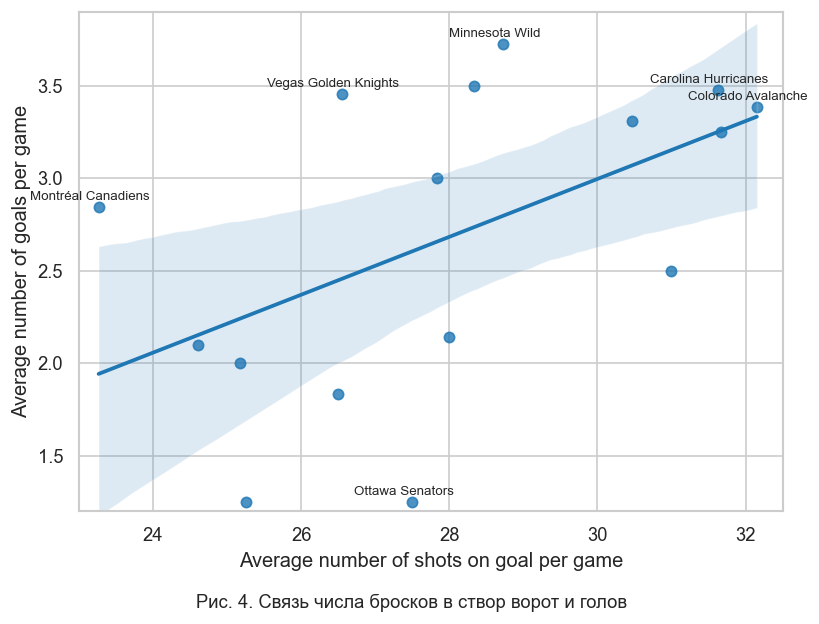

In [ ]:
# Строю регрессионную диаграмму и добавляю подписи к наиболее заметным командам.
plt.figure(figsize=(7, 5))
sns.regplot(
    data=avgshots,
    x='Shot',
    y='Goal',
    ci=95,
    scatter_kws={'s': 38, 'color': '#1f77b4'},
    line_kws={'color': '#1f77b4'}
)

# Подписываю наиболее показательные точки, как на рисунке из условия.
label_teams = [
    'Minnesota Wild', 'Vegas Golden Knights', 'Carolina Hurricanes',
    'Colorado Avalanche', 'Montréal Canadiens', 'Ottawa Senators'
]
for team in label_teams:
    row = avgshots.loc[team]
    plt.text(row['Shot'] - 0.12, row['Goal'] + 0.04,
             team, fontsize=8, ha='center')

plt.xlabel('Average number of shots on goal per game')
plt.ylabel('Average number of goals per game')
plt.xlim(23, 32.5)
plt.ylim(1.2, 3.9)
plt.tight_layout()
plt.figtext(0.5, -0.03,
            'Рис. 4. Связь числа бросков в створ ворот и голов',
            ha='center', fontsize=11)
plt.show()

correlation = avgshots['Shot'].corr(avgshots['Goal'])
line = np.polyfit(avgshots['Shot'], avgshots['Goal'], 1)
print(f'Корреляция: {correlation:.3f}')
print(f'Наклон линии регрессии: {line[0]:.3f}')

На графике каждая точка соответствует одной команде. Регрессионная линия имеет положительный наклон, а коэффициент корреляции равен 0.521, поэтому связь можно назвать умеренной положительной: большее число бросков в створ обычно связано с большим числом голов. Однако точки заметно отклоняются от линии. Например, Minnesota Wild забивали больше ожидаемого по числу бросков, а Dallas Stars — меньше, поэтому одной интенсивности бросков недостаточно для объяснения результата. Кроме того, выборка содержит только 16 команд.

## Задача 14. Игра с наибольшим числом ударов по воротам

In [ ]:
# Оставляю все четыре типа бросков и ищу матч с максимальным их количеством.
all_shots = events[events['Play Type'].isin(
    ['shot-on-goal', 'goal', 'missed-shot', 'blocked-shot']
)].copy()
shot_numbers = all_shots.groupby('Game ID').size()
max_game = shot_numbers.idxmax()

print('Максимальное число ударов:', int(shot_numbers.loc[max_game]))
print('Игра:', gameInfo(max_game))
print('\nРазбиение по типам:')
print(all_shots[all_shots['Game ID'] == max_game]['Play Type'].value_counts())

Максимальное число ударов: 208
Игра: Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)

Разбиение по типам:
Play Type
shot-on-goal    83
missed-shot     66
blocked-shot    54
goal             5
Name: count, dtype: int64


В этом пункте учитываются четыре вида событий: голы, точные броски, промахи и заблокированные броски. Максимум равен 208 и достигается в матче Carolina Hurricanes — Ottawa Senators, завершившемся со счетом 3:2 после двух овертаймов. Включение заблокированных бросков важно: это события, при которых команда нанесла попытку броска, хотя шайба не дошла до ворот. Именно координаты всех 208 событий используются на следующем рисунке.

## Задача 15. Координаты бросков в самой бросковой игре

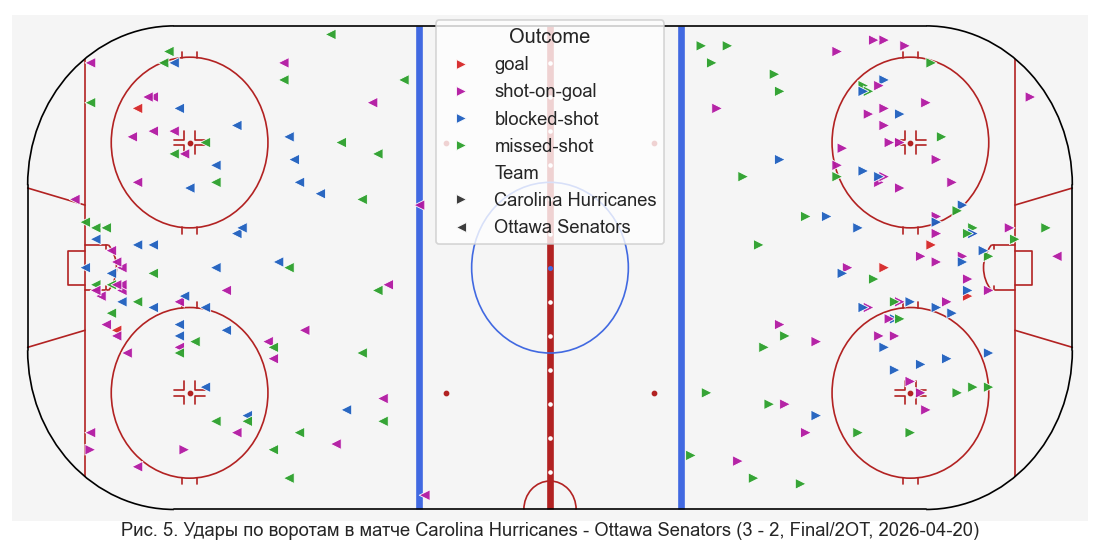

In [ ]:
# Отражаю координаты в нечетных периодах и рисую все броски на хоккейной площадке.
from rink import plot_rink

rink_shots = all_shots[all_shots['Game ID'] == max_game].copy()
rink_shots['Team'] = rink_shots['Team Making the Play']
rink_shots['X plot'] = rink_shots['X Coordinate on the Ice Rink']
rink_shots['Y plot'] = rink_shots['Y Coordinate on the Ice Rink']

# В нечетных периодах команды меняются сторонами, поэтому отражаю координаты.
odd_period = rink_shots['Period'] % 2 == 1
rink_shots.loc[odd_period, 'X plot'] = -rink_shots.loc[odd_period, 'X plot']
rink_shots.loc[odd_period, 'Y plot'] = -rink_shots.loc[odd_period, 'Y plot']

plt.figure(figsize=(9, 4.3))
plot_rink(False)
sns.scatterplot(
    data=rink_shots,
    x='X plot',
    y='Y plot',
    hue='Play Type',
    hue_order=['goal', 'shot-on-goal', 'blocked-shot', 'missed-shot'],
    palette={
        'goal': '#d62728',
        'shot-on-goal': '#b218a2',
        'blocked-shot': '#1f5fbf',
        'missed-shot': '#2ca02c'
    },
    style='Team',
    style_order=['Carolina Hurricanes', 'Ottawa Senators'],
    markers={'Carolina Hurricanes': '>', 'Ottawa Senators': '<'},
    s=42,
    alpha=0.95,
    legend='full'
)
plt.xlim(-103, 103)
plt.ylim(-45, 45)
plt.xlabel('')
plt.ylabel('')
plt.axis('off')
handles, labels = plt.gca().get_legend_handles_labels()
# Seaborn добавляет название переменной Play Type отдельной строкой;
# убираю его, чтобы заголовок легенды совпадал с примером: Outcome.
if labels and labels[0] == 'Play Type':
    handles = handles[1:]
    labels = labels[1:]
plt.legend(
    handles,
    labels,
    title='Outcome',
    loc='upper center',
    bbox_to_anchor=(0.5, 0.99),
    frameon=True,
    ncol=1,
    borderaxespad=0.2
)
plt.tight_layout(pad=0.1)
plt.figtext(
    0.5, -0.02,
    'Рис. 5. Удары по воротам в матче Carolina Hurricanes - Ottawa Senators '
    '(3 - 2, Final/2OT, 2026-04-20)',
    ha='center', fontsize=11
)
plt.show()

На рисунке 5 цвет кодирует исход броска в том же порядке, что и в примере: `goal`, `shot-on-goal`, `blocked-shot`, `missed-shot`. Форма маркера кодирует команду: вправо направлены треугольники Carolina Hurricanes, влево — Ottawa Senators. Легенда объединяет обе переменные и размещена по центру сверху, чтобы не закрывать зоны бросков у бортов. После отражения координат в нечетных периодах гости всегда находятся слева, хозяева — справа.

## Задача 16. Десять лучших снайперов плей-офф

In [ ]:
# Для списка снайперов считаю только первые поля событий с типом goal.
goal_events = events[events['Play Type'].eq('goal')].dropna(
    subset=['Player in the Event #1']
)
goals = goal_events.groupby('Player in the Event #1').size()
goals = goals.sort_values(ascending=False).head(10)
goals.name = 'Goals'
print(goals.to_frame())

                        Goals
Player in the Event #1       
Brett Howden               14
Pavel Dorofeyev            12
Logan Stankoven            11
Mitch Marner               10
Jordan Staal                8
Nikolaj Ehlers              8
Mark Stone                  7
Matt Boldy                  7
Nathan MacKinnon            7
Taylor Hall                 7


Снайперы считаются по полю `Player in the Event #1` только для событий `goal`, то есть в подсчет не попадают ассисты. Brett Howden забил 14 голов, Pavel Dorofeyev — 12, Logan Stankoven — 11, а Mitch Marner — 10. У нескольких игроков по 7 голов, поэтому в десятке есть совпадения по результату на последнем месте.

## Задача 17. Десять лучших игроков по голевым передачам

In [ ]:
# Объединяю два поля ассистов в один столбец и считаю передачи каждого игрока.
assist_events = events[events['Play Type'].eq('goal')][
    ['Player in the Event #2', 'Player in the Event #3']
].melt(value_name='Player').dropna(subset=['Player'])
assists = assist_events.groupby('Player').size().sort_values(ascending=False).head(10)
assists.name = 'Assists'
print(assists.to_frame())

                 Assists
Player                  
Jack Eichel           20
Mitch Marner          19
Lane Hutson           13
Jackson Blake         13
Nick Suzuki           12
Taylor Hall           12
Shea Theodore         12
Martin Necas          12
Kirill Kaprizov       11
Quinn Hughes          11


Ассист засчитывается отдельно по каждому из двух полей: `Player in the Event #2` и `Player in the Event #3`. Пустые значения удаляются, чтобы не считать отсутствие второго ассистента игроком. Jack Eichel набрал 20 голевых передач, Mitch Marner — 19, а Lane Hutson и Jackson Blake — по 13. Это именно передачи в голах, записанных в исходных событиях.

## Задача 18. Десять лучших игроков по системе гол плюс пас

In [ ]:
# Складываю голы и передачи, чтобы получить очки по системе гол плюс пас.
points = goals.add(assists, fill_value=0)
# Для этой задачи нужны все игроки, поэтому пересчитываю серии без head(10).
goals_all = goal_events.groupby('Player in the Event #1').size()
assists_all = assist_events.groupby('Player').size()
points = goals_all.add(assists_all, fill_value=0).sort_values(ascending=False).head(10)
points.name = 'Points'
print(points.to_frame())

                 Points
Mitch Marner       29.0
Jack Eichel        22.0
Jackson Blake      20.0
Taylor Hall        19.0
Brett Howden       18.0
Nikolaj Ehlers     18.0
Shea Theodore      18.0
Pavel Dorofeyev    16.0
Lane Hutson        16.0
Logan Stankoven    16.0


Очки получены сложением двух независимых серий: голов и голевых передач. Mitch Marner занимает первое место с 29 очками (10 голов и 19 передач), Jack Eichel — второе с 22 очками, Jackson Blake — третье с 20. При одинаковом числе очков порядок внутри последней части десятки определяется сортировкой pandas, поэтому все показанные значения 16 являются корректными.

## Задача 19. Среднее число бросков в створ за игру у игроков

In [ ]:
# Собираю набор «игрок — матч» по составам на льду, чтобы нулевые матчи тоже учитывались.
roster_columns = []
for side in ['Away', 'Home']:
    for number in range(1, 7):
        roster_columns.append(f"{side} Team's Player on the Ice #{number}")
    roster_columns.append(f"{side} Team's Goalie")

player_games = events[['Game ID'] + roster_columns].melt(
    id_vars='Game ID', value_name='Player'
)
player_games = player_games.dropna(subset=['Player'])[['Game ID', 'Player']]
player_games = player_games.drop_duplicates()

# Сначала считаю броски каждого игрока в каждом матче.
player_shots = events[events['Play Type'].isin(['shot-on-goal', 'goal'])].dropna(
    subset=['Player in the Event #1']
).rename(columns={'Player in the Event #1': 'Player'})
player_game_shots = player_shots.groupby(['Player', 'Game ID']).size()
player_game_shots.name = 'Shots'
player_game_shots = player_game_shots.reset_index()

# Объединяю события с играми, где игрок был на льду, и заполняю нули.
avg_player_shots = player_games.merge(
    player_game_shots, on=['Player', 'Game ID'], how='left'
)
avg_player_shots['Shots'] = avg_player_shots['Shots'].fillna(0)
avg_player_shots = avg_player_shots.groupby('Player').agg(
    Games=('Game ID', 'nunique'),
    Total=('Shots', 'sum'),
    Average=('Shots', 'mean')
).reset_index()
avg_player_shots = avg_player_shots.sort_values(
    ['Average', 'Games', 'Player'], ascending=[False, False, True]
).head(10).set_index('Player')
avg_player_shots.columns = ['Games', 'Total', 'Average shots on goal per game']
print(avg_player_shots.round(3))

                  Games  Total  Average shots on goal per game
Player                                                        
Jason Robertson       6   30.0                           5.000
Dylan Guenther        6   27.0                           4.500
Nikita Kucherov       7   31.0                           4.429
Matt Boldy           11   48.0                           4.364
Quinton Byfield       4   17.0                           4.250
Darren Raddysh        7   28.0                           4.000
Joel Eriksson Ek      6   24.0                           4.000
Alex Laferriere       4   15.0                           3.750
David Pastrnak        6   22.0                           3.667
Nathan MacKinnon     13   47.0                           3.615


Среднее теперь считается по всем матчам, в которых игрок присутствовал в составе на льду: сначала формируется таблица «игрок — матч», а затем к ней присоединяется число бросков. Если игрок был заявлен и не нанес ни одного броска в створ, в этот матч добавляется ноль. В результате лидирует Jason Robertson: 30 бросков за 6 матчей, то есть 5.000 за матч. У Nathan MacKinnon 47 бросков за 13 матчей (3.615); это ниже, чем если бы учитывать только 12 матчей с ненулевым результатом. Такой способ делает знаменатель прозрачным и показывает, что малое число матчей может заметно влиять на верхнюю часть списка.

## Задача 20. Среднее число силовых приемов за игру у игроков

In [ ]:
# Для силовых приемов использую тот же набор «игрок — матч», включая матчи без hit.
player_hits = events[events['Play Type'].eq('hit')].dropna(
    subset=['Player in the Event #1']
).rename(columns={'Player in the Event #1': 'Player'})
player_game_hits = player_hits.groupby(['Player', 'Game ID']).size()
player_game_hits.name = 'Hits'
player_game_hits = player_game_hits.reset_index()

avg_player_hits = player_games.merge(
    player_game_hits, on=['Player', 'Game ID'], how='left'
)
avg_player_hits['Hits'] = avg_player_hits['Hits'].fillna(0)
avg_player_hits = avg_player_hits.groupby('Player').agg(
    Games=('Game ID', 'nunique'),
    Total=('Hits', 'sum'),
    Average=('Hits', 'mean')
).reset_index()
avg_player_hits = avg_player_hits.sort_values(
    ['Average', 'Games', 'Player'], ascending=[False, False, True]
).head(10).set_index('Player')
avg_player_hits.columns = ['Games', 'Total', 'Average hits per game']
print(avg_player_hits.round(3))

                    Games  Total  Average hits per game
Player                                                 
Lawson Crouse           6   38.0                  6.333
Alex Turcotte           1    6.0                  6.000
Alexander Petrovic      1    6.0                  6.000
Yakov Trenin            9   51.0                  5.667
Dylan Cozens            4   22.0                  5.500
Vasily Podkolzin        6   32.0                  5.333
Ivan Barbashev         22  110.0                  5.000
Marcus Foligno         11   55.0                  5.000
Carl Grundstrom         3   15.0                  5.000
Owen Tippett            6   29.0                  4.833


Для силовых приемов используется тот же принцип: знаменатель — все матчи, где игрок присутствовал в составе на льду, а не только матчи, в которых записан хотя бы один `hit`. Lawson Crouse провел 38 приемов за 6 матчей (6.333 за матч). Alex Turcotte и Alexander Petrovic имеют по 6.000, но каждый показатель получен только за одну игру, поэтому это самый заметный результат с маленькой выборкой. Yakov Trenin показывает 5.667 за 9 матчей и поэтому дает более устойчивую оценку.

## Задача 21. Вратари, сыгравшие хотя бы одну игру без пропущенных шайб

In [ ]:
# Собираю все пары «вратарь — матч», включая замены в течение одной игры.
goalie_columns = ["Away Team's Goalie", "Home Team's Goalie"]
goalie_games = events[['Game ID'] + goalie_columns].melt(
    id_vars='Game ID', value_name='Goalie'
)
goalie_games = goalie_games.dropna(subset=['Goalie'])[['Game ID', 'Goalie']]
goalie_games = goalie_games.drop_duplicates()

# Гол относится к вратарю защищающейся команды в момент события.
goals = events[events['Play Type'].eq('goal')].copy()
goals['Goalie'] = np.where(
    goals['Team Making the Play'].eq(goals['Away Team']),
    goals["Home Team's Goalie"],
    np.where(
        goals['Team Making the Play'].eq(goals['Home Team']),
        goals["Away Team's Goalie"],
        np.nan
    )
)
# При пустых воротах оба поля могут быть NaN, поэтому такой гол не приписываю вратарю.
goals_against = goals.dropna(subset=['Goalie']).groupby(
    ['Goalie', 'Game ID']
).size().rename('Goals against').reset_index()

goalie_games = goalie_games.merge(
    goals_against, on=['Goalie', 'Game ID'], how='left'
)
goalie_games['Goals against'] = goalie_games['Goals against'].fillna(0)
shutout_games = goalie_games[goalie_games['Goals against'].eq(0)]
shutout_goalies = sorted(shutout_games['Goalie'].unique())
print('Матчи без пропущенных шайб у вратаря:')
print(shutout_games.sort_values(['Goalie', 'Game ID']).to_string(index=False))
print('Вратари:', shutout_goalies)
print('Количество:', len(shutout_goalies))

Матчи без пропущенных шайб у вратаря:
   Game ID             Goalie  Goals against
2025030126 Andrei Vasilevskiy            0.0
2025030146      Arturs Silovs            0.0
2025030413      Brandon Bussi            0.0
2025030416      Brandon Bussi            0.0
2025030142         Dan Vladar            0.0
2025030146         Dan Vladar            0.0
2025030131  Frederik Andersen            0.0
2025030221  Frederik Andersen            0.0
2025030314  Frederik Andersen            0.0
2025030126        Jakub Dobes            0.0
2025030114   Joonas Korpisalo            0.0
2025030235    Scott Wedgewood            0.0
Вратари: ['Andrei Vasilevskiy', 'Arturs Silovs', 'Brandon Bussi', 'Dan Vladar', 'Frederik Andersen', 'Jakub Dobes', 'Joonas Korpisalo', 'Scott Wedgewood']
Количество: 8


Проверка ведется на уровне пары «вратарь — конкретный матч». Гол засчитывается вратарю защищающейся команды, указанному в строке события; если оба поля вратарей пусты, это эпизод с пустыми воротами, и гол не приписывается никому. Такой учет находит 8 вратарей: Andrei Vasilevskiy, Arturs Silovs, Brandon Bussi, Dan Vladar, Frederik Andersen, Jakub Dobes, Joonas Korpisalo и Scott Wedgewood. Это шире списка по нулевому финальному счету команды: например, Joonas Korpisalo вышел на замену уже после шести пропущенных Boston шайб, а Brandon Bussi играл часть матча, в котором Carolina пропустила гол в пустые ворота, и в его время на льду шайб не пропустил.

Дополнительный вопрос: как часто команда, открывшая счет, выигрывает матч? Для каждой игры берется самое раннее событие `goal`, его команда сравнивается с финальным счетом. Такой вопрос содержательно связывает временной порядок событий с результатом игры и не требует дополнительных данных.

In [ ]:
# Для дополнительного вопроса нахожу самое раннее событие goal в каждой игре.
first_goal_events = events[events['Play Type'].eq('goal')].sort_values(
    ['Game ID', 'Play ID']
).groupby('Game ID').first()

first_goal_wins = 0
for game_id, first_goal in first_goal_events.iterrows():
    game = games.loc[game_id]
    first_team = first_goal['Team Making the Play']
    if first_team == game['Away Team']:
        win = game['Away Score'] > game['Home Score']
    else:
        win = game['Home Score'] > game['Away Score']
    if win:
        first_goal_wins += 1

number_of_games = len(first_goal_events)
share_first_goal_wins = first_goal_wins / number_of_games
print(f'Команда, забившая первой, выиграла {first_goal_wins} из {number_of_games} игр.')
print(f'Доля таких побед: {share_first_goal_wins:.3f}')

Команда, забившая первой, выиграла 56 из 82 игр.
Доля таких побед: 0.683


Команда, забившая первой, победила в 56 из 82 матчей, то есть в 0.683 (68.3%) случаев. Значит, первый гол заметно повышает шансы на победу, но не гарантирует ее: в 26 матчах соперник смог сравнять счет и выиграть. Это описательная связь для данного плей-офф, а не доказательство причинного эффекта.

## Общий вывод по анализу

В наборе 82 матча и 29 710 событий, поэтому выводы основаны на подробной последовательности эпизодов, а не только на финальных счетах. Типичный матч закончился примерно шестью голами, но разброс оказался большим: от одной шайбы до пятнадцати. Особенно необычны две игры со счетом 1:0, обе решившиеся в овертайме, и матч Colorado Avalanche — Minnesota Wild со счетом 9:6.

Распределение расстояний показывает, что основная часть бросков выполняется с близких и средних дистанций. При этом у точных бросков есть длинный хвост почти до 190 футов. Это редкие дальние эпизоды, включая броски со своей половины площадки и ситуации с пустыми воротами; поэтому среднее расстояние здесь немного выше медианы и его нельзя трактовать как обычную дистанцию атаки.

Самым бросковым стал матч Carolina Hurricanes — Ottawa Senators: 208 событий четырех типов, хотя итоговый счет был всего 3:2 и игра дошла до второго овертайма. Это хорошо показывает, что количество попыток и количество голов измеряют разные стороны матча. Связь между средним числом бросков в створ и средним числом голов положительная, но умеренная (корреляция 0.521), поэтому точность реализации и качество моментов также существенно влияют на результат. В индивидуальных рейтингах среднее считается по матчам присутствия в составе, поэтому нулевые матчи не скрываются. Для вратарей отдельно учитываются замены и голы в пустые ворота: это дает восемь вратарей с матчем без пропущенной шайбы.

Наконец, команда, забившая первой, победила в 56 из 82 игр (68.3%). Первый гол связан с преимуществом, но 26 матчей закончились победой команды, которая открыла счет позже или смогла переломить ход игры. Эти результаты вместе показывают, что в плей-офф важны не один показатель, а сочетание темпа бросков, точности, реализации, игры вратарей и развития матча во времени.